In [1]:
!pip install -q sentence-transformers faiss-cpu scipy nltk

import os
import re
import gc
import time
import math
import json
import hashlib
import platform
import unicodedata
from collections import defaultdict, Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import spearmanr, wilcoxon
import nltk
from nltk.stem import PorterStemmer
import torch
import faiss
import sentence_transformers
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.max_columns", 20)
np.random.seed(42)
torch.manual_seed(42)
BM25_K1 = 1.5
BM25_B = 0.75
DENSE_MODEL_NAME = "sentence-transformers/multi-qa-MiniLM-L6-cos-v1"
RRF_K = 60
RRF_DEPTH = 500

print("=== ENVIRONMENT & CONFIGURATION ===")
print(f"Python:                {platform.python_version()}")
print(f"PyTorch:               {torch.__version__} (CUDA: {torch.cuda.is_available()})")
print(f"FAISS:                 {faiss.__version__}")
print(f"Sentence-Transformers: {sentence_transformers.__version__}")
print(f"Dense Encoder:         {DENSE_MODEL_NAME}")
print(f"BM25 Params:           k1={BM25_K1}, b={BM25_B} | RRF: k={RRF_K}, depth={RRF_DEPTH}")

=== ENVIRONMENT & CONFIGURATION ===
Python:                3.13.16
PyTorch:               2.11.0+cu130 (CUDA: True)
FAISS:                 1.15.1
Sentence-Transformers: 5.7.0
Dense Encoder:         sentence-transformers/multi-qa-MiniLM-L6-cos-v1
BM25 Params:           k1=1.5, b=0.75 | RRF: k=60, depth=500


In [2]:
DATASET_FILES = [
    "News_Category_Dataset_v3.json.zip",
    "News_Category_Dataset_v3.json",
    "news_corpus.csv"
]

loaded_path = next((p for p in DATASET_FILES if os.path.exists(p)), None)
if loaded_path is None:
    try:
        from google.colab import files
        print("Please upload News_Category_Dataset_v3.json.zip (or .json):")
        uploaded = files.upload()
        loaded_path = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError("Place News_Category_Dataset_v3.json.zip in the working directory.")
if loaded_path.endswith(".csv"):
    df = pd.read_csv(loaded_path)
    df = df.reset_index(drop=True)
    if "doc_id" not in df.columns:
        df["doc_id"] = [f"N{i:06d}" for i in range(len(df))]
else:
    df = pd.read_json(loaded_path, lines=True)
    df = df.reset_index(drop=True)
    df["doc_id"] = [f"N{i:06d}" for i in range(len(df))]

required_cols = {"doc_id", "headline", "short_description", "category", "date"}
assert required_cols.issubset(set(df.columns)), f"Missing columns: {required_cols - set(df.columns)}"

df["headline"] = df["headline"].fillna("").astype(str)
df["short_description"] = df["short_description"].fillna("").astype(str)
df["category"] = df["category"].fillna("UNKNOWN").astype(str)
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df["year"] = df["date"].dt.year.fillna(0).astype(int)
df["search_text"] = (
    df["headline"].str.strip() + " " + df["short_description"].str.strip()
).str.strip()

doc_id_to_idx = {doc_id: idx for idx, doc_id in enumerate(df["doc_id"])}
idx_to_doc_id = df["doc_id"].to_numpy()

corpus_hash = hashlib.md5(
    (str(len(df)) + df["search_text"].iloc[0] + df["search_text"].iloc[-1]).encode("utf-8")
).hexdigest()[:10]

print(f"Loaded '{loaded_path}': {len(df):,} articles | Date range: {df['date'].min().date()} to {df['date'].max().date()} | Hash: {corpus_hash}")
display(df[["doc_id", "headline", "short_description", "category", "date"]].head(5))

Please upload News_Category_Dataset_v3.json.zip (or .json):


Saving News_Category_Dataset_v3.json.zip to News_Category_Dataset_v3.json.zip
Loaded 'News_Category_Dataset_v3.json.zip': 209,527 articles | Date range: 2012-01-28 to 2022-09-23 | Hash: 48ddc3b4b0


,doc_id,headline,short_description,category,date
0,N000000,Over 4 Million Americans Roll Up Sleeves For Omicron-Targeted COVID Boosters,Health experts said it is too early to predict whether demand would match up with the 171 million doses of the new boosters the U.S. ord...,U.S. NEWS,2022-09-23
1,N000001,"American Airlines Flyer Charged, Banned For Life After Punching Flight Attendant On Video","He was subdued by passengers and crew when he fled to the back of the aircraft after the confrontation, according to the U.S. attorney's...",U.S. NEWS,2022-09-23
2,N000002,23 Of The Funniest Tweets About Cats And Dogs This Week (Sept. 17-23),"""Until you have a dog you don't understand what could be eaten.""",COMEDY,2022-09-23
3,N000003,The Funniest Tweets From Parents This Week (Sept. 17-23),"""Accidentally put grown-up toothpaste on my toddler’s toothbrush and he screamed like I was cleaning his teeth with a Carolina Reaper di...",PARENTING,2022-09-23
4,N000004,Woman Who Called Cops On Black Bird-Watcher Loses Lawsuit Against Ex-Employer,Amy Cooper accused investment firm Franklin Templeton of unfairly firing her and branding her a racist after video of the Central Park e...,U.S. NEWS,2022-09-22


In [5]:
NEGATION_WORDS = {"no", "not", "never", "without", "neither", "nor", "none", "nobody", "nothing", "nowhere"}

BASE_STOPWORDS = {
    "a", "an", "the", "and", "or", "but", "if", "because", "as", "until", "while",
    "of", "at", "by", "for", "with", "about", "into", "through", "during", "before",
    "after", "above", "below", "to", "from", "up", "down", "in", "out", "on", "off",
    "over", "under", "again", "further", "then", "once", "here", "there", "when",
    "where", "why", "how", "all", "any", "both", "each", "few", "more", "most",
    "other", "some", "such", "only", "own", "same", "so", "than", "too", "very",
    "can", "will", "just", "should", "now", "is", "are", "was", "were", "be", "been",
    "being", "have", "has", "had", "having", "do", "does", "did", "doing", "would",
    "could", "ought", "i", "me", "my", "myself", "we", "our", "ours", "ourselves",
    "you", "your", "yours", "yourself", "he", "him", "his", "himself", "she", "her",
    "hers", "herself", "it", "its", "itself", "they", "them", "their", "theirs",
    "themselves", "what", "which", "who", "whom", "this", "that", "these", "those",
    "am", "said", "says"
} - NEGATION_WORDS

CONTRACTIONS_MAP = {
    r"\bwon't\b": "will not",
    r"\bcan't\b": "cannot",
    r"\bshan't\b": "shall not",
    r"\bain't\b": "is not",
    r"n't\b": " not",
    r"'re\b": " are",
    r"'ve\b": " have",
    r"'ll\b": " will",
    r"'d\b": " would",
    r"\bi'm\b": "i am",
    r"\blet's\b": "let us",
}

stemmer = PorterStemmer()
STEM_CACHE = {}

def stem_word(w):
    if len(w) <= 2:
        return w
    if w not in STEM_CACHE:
        STEM_CACHE[w] = stemmer.stem(w)
    return STEM_CACHE[w]

def strip_accents(text):
    normalized = unicodedata.normalize("NFKD", text)
    return "".join(c for c in normalized if not unicodedata.combining(c))

def preprocess_text(text, remove_stopwords=True, use_stemming=False):
    if not text:
        return []
    s = str(text).lower().replace("’", "'").replace("‘", "'")
    s = strip_accents(s)
    s = re.sub(
        r"\b([a-z])\.([a-z])\.(?:([a-z])\.)?",
        lambda m: "".join(g for g in m.groups() if g),
        s
    )
    s = re.sub(r"\b([a-z])\.([a-z])\b", r"\1\2", s)
    for pat, repl in CONTRACTIONS_MAP.items():
        s = re.sub(pat, repl, s)
    s = re.sub(r"'s\b", "", s)
    s = re.sub(r"s'\b", "s", s)
    s = s.replace("-", " ")
    tokens = re.findall(r"\b[a-z0-9]+\b", s)
    if remove_stopwords:
        tokens = [t for t in tokens if (t not in BASE_STOPWORDS) and (len(t) > 1 or t in NEGATION_WORDS)]
    else:
        tokens = [t for t in tokens if len(t) > 1]
    if use_stemming:
        tokens = [stem_word(t) for t in tokens]
    return tokens

assert "erdogan" in preprocess_text("President Erdoğan visited the U.S.")
assert "us" in preprocess_text("U.S. officials")
assert "not" in preprocess_text("COVID vaccine news that isn't about boosters", use_stemming=False)
assert "without" in preprocess_text("People without water after storm", use_stemming=False)
assert "toyota" in preprocess_text("Toyota's bird-watcher don't", use_stemming=False)
assert "bird" in preprocess_text("Toyota's bird-watcher don't", use_stemming=False)
assert preprocess_text("recalls defective cars", use_stemming=True)[0] == preprocess_text("recall defective car", use_stemming=True)[0]
print("All text-preprocessing unit tests passed successfully!")

All text-preprocessing unit tests passed successfully!


In [6]:
class ScratchBM25Engine:
    def __init__(self, k1=1.5, b=0.75, use_stemming=False, name="Engine A: BM25"):
        self.k1 = k1
        self.b = b
        self.use_stemming = use_stemming
        self.name = name
        self.N = 0
        self.avgdl = 0.0
        self.doc_len = None
        self.doc_token_sets = []
        self.df_table = {}
        self.idf_table = {}
        self.inverted_index = {}
        self.build_time_sec = 0.0
        self.memory_mb = 0.0

    def fit(self, corpus_texts):
        t0 = time.time()
        self.N = len(corpus_texts)
        self.doc_len = np.zeros(self.N, dtype=np.int32)
        self.doc_token_sets = [None] * self.N
        temp_postings = defaultdict(lambda: ([], []))
        for doc_idx, text in enumerate(corpus_texts):
            tokens = preprocess_text(text, remove_stopwords=True, use_stemming=self.use_stemming)
            self.doc_len[doc_idx] = len(tokens)
            self.doc_token_sets[doc_idx] = set(tokens)
            tf_counter = Counter(tokens)
            for term, tf in tf_counter.items():
                doc_list, tf_list = temp_postings[term]
                doc_list.append(doc_idx)
                tf_list.append(tf)
        self.avgdl = float(np.mean(self.doc_len))
        total_bytes = self.doc_len.nbytes
        for term, (doc_list, tf_list) in temp_postings.items():
            n_t = len(doc_list)
            self.df_table[term] = n_t
            self.idf_table[term] = math.log(1.0 + (self.N - n_t + 0.5) / (n_t + 0.5))
            d_arr = np.array(doc_list, dtype=np.int32)
            tf_arr = np.array(tf_list, dtype=np.float32)
            self.inverted_index[term] = (d_arr, tf_arr)
            total_bytes += d_arr.nbytes + tf_arr.nbytes

        self.build_time_sec = time.time() - t0
        self.memory_mb = total_bytes / (1024.0 ** 2)
        print(
            f"[{self.name}] Indexed {self.N:,} docs | Vocab: {len(self.inverted_index):,} terms | "
            f"AvgDL: {self.avgdl:.2f} | Time: {self.build_time_sec:.2f}s | Index RAM: {self.memory_mb:.2f} MB"
        )
        return self

    def score_all(self, query_text):
        q_tokens = preprocess_text(query_text, remove_stopwords=True, use_stemming=self.use_stemming)
        scores = np.zeros(self.N, dtype=np.float32)
        if not q_tokens:
            return scores
        q_counts = Counter(q_tokens)
        for term, q_tf in q_counts.items():
            if term not in self.inverted_index:
                continue
            doc_indices, doc_tfs = self.inverted_index[term]
            idf = self.idf_table[term]
            d_lens = self.doc_len[doc_indices]
            denom = doc_tfs + self.k1 * (1.0 - self.b + self.b * (d_lens / self.avgdl))
            scores[doc_indices] += idf * ((doc_tfs * (self.k1 + 1.0)) / denom) * q_tf
        return scores

    def search(self, query_text, top_k=100):
        scores = self.score_all(query_text)
        pos_mask = scores > 0.0
        pos_indices = np.nonzero(pos_mask)[0]
        if pos_indices.size == 0:
            return np.array([], dtype=np.int32), np.array([], dtype=np.float32)
        pos_scores = scores[pos_indices]
        order = np.lexsort((pos_indices, -pos_scores))[:top_k]
        top_idx = pos_indices[order].astype(np.int32)
        top_sc = pos_scores[order].astype(np.float32)
        return top_idx, top_sc

corpus_texts = df["search_text"].tolist()
bm25_engine = ScratchBM25Engine(k1=BM25_K1, b=BM25_B, use_stemming=True, name="Engine A: BM25 (Stemmed)").fit(corpus_texts)
bm25_unstemmed_engine = ScratchBM25Engine(k1=BM25_K1, b=BM25_B, use_stemming=False, name="Engine A (Ablation): BM25 (Unstemmed)").fit(corpus_texts)

[Engine A: BM25 (Stemmed)] Indexed 209,527 docs | Vocab: 61,972 terms | AvgDL: 17.79 | Time: 27.12s | Index RAM: 26.66 MB
[Engine A (Ablation): BM25 (Unstemmed)] Indexed 209,527 docs | Vocab: 87,909 terms | AvgDL: 17.79 | Time: 55.36s | Index RAM: 27.02 MB


In [7]:
class DenseFAISSEngine:
    def __init__(self, model_name, corpus_list, corpus_fingerprint, name="Engine B: Dense"):
        self.model_name = model_name
        self.name = name
        self.device = "cuda" if torch.cuda.is_available() else "cpu"
        slug = re.sub(r"[^a-zA-Z0-9_-]", "_", model_name)
        self.cache_path = f"embeddings_{slug}_{corpus_fingerprint}.npy"
        legacy_cache = "huffpost_embeddings_sentence-transformers_all-MiniLM-L6-v2.npy"
        self.encoder = SentenceTransformer(model_name, device=self.device)
        t0 = time.time()
        if os.path.exists(self.cache_path):
            print(f"[{self.name}] Loading fingerprinted embeddings from '{self.cache_path}'...")
            self.embeddings = np.load(self.cache_path)
        else:
            print(f"[{self.name}] Encoding {len(corpus_list):,} articles with '{model_name}' on {self.device.upper()}...")
            self.embeddings = self.encoder.encode(
                corpus_list,
                batch_size=512 if self.device == "cuda" else 128,
                show_progress_bar=True,
                convert_to_numpy=True,
                normalize_embeddings=True
            ).astype(np.float32)
            np.save(self.cache_path, self.embeddings)
            print(f"[{self.name}] Saved fingerprinted cache to '{self.cache_path}'.")
        dim = self.embeddings.shape[1]
        self.index = faiss.IndexFlatIP(dim)
        self.index.add(self.embeddings)
        self.build_time_sec = time.time() - t0
        self.memory_mb = self.embeddings.nbytes / (1024.0 ** 2)
        print(
            f"[{self.name}] FAISS IndexFlatIP ready: {self.index.ntotal:,} vectors (dim={dim}) | "
            f"Time: {self.build_time_sec:.2f}s | Index RAM: {self.memory_mb:.2f} MB"
        )

    def search(self, query_text, top_k=100):
        q_vec = self.encoder.encode(
            [query_text],
            convert_to_numpy=True,
            normalize_embeddings=True
        ).astype(np.float32)
        scores, indices = self.index.search(q_vec, top_k)
        return indices[0].astype(np.int32), scores[0].astype(np.float32)

dense_engine = DenseFAISSEngine(
    DENSE_MODEL_NAME,
    corpus_texts,
    corpus_fingerprint=corpus_hash,
    name="Engine B: Dense (multi-qa-MiniLM-L6)"
)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (6 outputs left out)

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

[Engine B: Dense (multi-qa-MiniLM-L6)] Encoding 209,527 articles with 'sentence-transformers/multi-qa-MiniLM-L6-cos-v1' on CUDA...


Batches:   0%|          | 0/410 [00:00<?, ?it/s]

[Engine B: Dense (multi-qa-MiniLM-L6)] Saved fingerprinted cache to 'embeddings_sentence-transformers_multi-qa-MiniLM-L6-cos-v1_48ddc3b4b0.npy'.
[Engine B: Dense (multi-qa-MiniLM-L6)] FAISS IndexFlatIP ready: 209,527 vectors (dim=384) | Time: 215.82s | Index RAM: 306.92 MB


In [8]:
class HybridRRFEngine:
    def __init__(self, bm25_eng, dense_eng, k=60, depth=500, w_bm25=0.5, name="Engine C: Hybrid (RRF)"):
        self.bm25 = bm25_eng
        self.dense = dense_eng
        self.k = k
        self.depth = depth
        self.w_bm25 = w_bm25
        self.w_dense = 1.0 - w_bm25
        self.name = name
        self.build_time_sec = bm25_eng.build_time_sec + dense_eng.build_time_sec
        self.memory_mb = bm25_eng.memory_mb + dense_eng.memory_mb

    def search(self, query_text, top_k=100):
        b_idx, _ = self.bm25.search(query_text, top_k=self.depth)
        d_idx, _ = self.dense.search(query_text, top_k=self.depth)
        rrf_scores = defaultdict(float)
        scale_b = self.w_bm25 * 2.0
        scale_d = self.w_dense * 2.0
        for rank_0, doc_idx in enumerate(b_idx):
            rrf_scores[int(doc_idx)] += scale_b / (self.k + rank_0 + 1)
        for rank_0, doc_idx in enumerate(d_idx):
            rrf_scores[int(doc_idx)] += scale_d / (self.k + rank_0 + 1)
        sorted_items = sorted(rrf_scores.items(), key=lambda item: (-item[1], item[0]))[:top_k]
        top_idx = np.array([item[0] for item in sorted_items], dtype=np.int32)
        top_sc = np.array([item[1] for item in sorted_items], dtype=np.float32)
        return top_idx, top_sc

hybrid_engine = HybridRRFEngine(
    bm25_engine, dense_engine, k=RRF_K, depth=RRF_DEPTH, w_bm25=0.5,
    name="Engine C: Hybrid (RRF)"
)
print(f"[{hybrid_engine.name}] Ready (k={RRF_K}, depth={RRF_DEPTH}).")

[Engine C: Hybrid (RRF)] Ready (k=60, depth=500).


In [9]:
QUERY_RULES = [
    {
        "query_id": "Q01",
        "family": "Negation",
        "mismatch_subtype": "NegationConstraint",
        "query": "COVID vaccine news that is not about booster shots",
        "topic_any": ["covid vaccine", "coronavirus vaccine", "moderna", "pfizer vaccine", "vaccinated"],
        "must_any": ["vaccine", "vaccinated", "vaccination", "shots"],
        "forbidden_any": ["booster", "boosters", "fourth dose", "third dose"],
        "year_range": None
    },
    {
        "query_id": "Q02",
        "family": "Negation",
        "mismatch_subtype": "NegationConstraint",
        "query": "airline flight disruptions and delays not caused by employee strikes",
        "topic_any": ["airline", "airlines", "flight", "flights", "passengers"],
        "must_any": ["canceled", "delays", "delayed", "stranded", "disruptions", "diverted", "unruly"],
        "forbidden_any": ["strike", "strikes", "striking", "walkout", "union", "picketing"],
        "year_range": None
    },
    {
        "query_id": "Q03",
        "family": "Negation",
        "mismatch_subtype": "NegationConstraint",
        "query": "Supreme Court rulings and justice confirmations without abortion cases",
        "topic_any": ["supreme court", "scotus", "chief justice", "kavanaugh", "gorsuch", "ketanji brown jackson"],
        "must_any": ["court", "justice", "justices", "ruling", "confirmation"],
        "forbidden_any": ["abortion", "roe v. wade", "roe", "planned parenthood", "reproductive"],
        "year_range": None
    },
    {
        "query_id": "Q04",
        "family": "Negation",
        "mismatch_subtype": "NegationConstraint",
        "query": "electric vehicles and clean energy cars not involving Tesla",
        "topic_any": ["electric vehicle", "electric vehicles", "electric car", "electric cars", "evcharging", "hybrid car"],
        "must_any": ["electric", "emissions", "battery", "automaker", "charging"],
        "forbidden_any": ["tesla", "elon musk", "musk"],
        "year_range": None
    },
    {
        "query_id": "Q05",
        "family": "Homonym",
        "mismatch_subtype": "Polysemy / Homonym",
        "query": "cricket insect life cycle and eating edible bugs",
        "topic_any": ["cricket", "crickets"],
        "must_any": ["insect", "insects", "bug", "bugs", "eat", "eats", "eating", "protein", "crushed crickets", "chirping"],
        "forbidden_any": ["world cup", "batsman", "bowler", "wicket", "test match", "ipl", "cricketer"],
        "year_range": None
    },
    {
        "query_id": "Q06",
        "family": "Homonym",
        "mismatch_subtype": "Polysemy / Homonym",
        "query": "wild turkey bird wildlife behavior and Thanksgiving pardon",
        "topic_any": ["turkey", "turkeys"],
        "must_any": ["bird", "birds", "thanksgiving", "pardon", "pardons", "wild", "feathers", "gobble", "roast"],
        "forbidden_any": ["erdogan", "istanbul", "ankara", "turkish", "syria", "nato", "coup"],
        "year_range": None
    },
    {
        "query_id": "Q07",
        "family": "Homonym",
        "mismatch_subtype": "Polysemy / Homonym",
        "query": "Apple orchard fruit harvest and cider recipes",
        "topic_any": ["apple", "apples"],
        "must_any": ["orchard", "fruit", "cider", "pie", "bake", "baking", "harvest", "tree", "trees", "recipe", "recipes"],
        "forbidden_any": ["iphone", "ipad", "macbook", "tim cook", "ios", "app store", "tech", "silicon valley"],
        "year_range": None
    },
    {
        "query_id": "Q08",
        "family": "Homonym",
        "mismatch_subtype": "Polysemy / Homonym",
        "query": "planetary mercury solar system astronomy mission",
        "topic_any": ["mercury"],
        "must_any": ["planet", "planets", "nasa", "space", "solar system", "orbit", "telescope", "astronomy", "sun"],
        "forbidden_any": ["fish", "seafood", "tuna", "poisoning", "toxic", "freddie mercury", "queen"],
        "year_range": None
    },
    {
        "query_id": "Q09",
        "family": "Temporal",
        "mismatch_subtype": "Temporal Window",
        "query": "Rio de Janeiro Summer Olympics 2016 coverage",
        "topic_any": ["olympics", "olympic", "rio"],
        "must_any": ["rio", "medal", "gold", "athletes", "swimmer", "gymnast", "usain bolt", "simone biles", "phelps"],
        "forbidden_any": ["tokyo 2020", "beijing 2022", "pyeongchang"],
        "year_range": (2016, 2016)
    },
    {
        "query_id": "Q10",
        "family": "Temporal",
        "mismatch_subtype": "Temporal Window",
        "query": "Dakota Access Pipeline Standing Rock protests in 2016 and 2017",
        "topic_any": ["dakota access", "standing rock"],
        "must_any": ["pipeline", "protesters", "protest", "tribe", "native american", "oil", "camp", "activists"],
        "forbidden_any": [],
        "year_range": (2016, 2017)
    },
    {
        "query_id": "Q11",
        "family": "Temporal",
        "mismatch_subtype": "Temporal Window",
        "query": "Hurricane Fiona Puerto Rico power blackout and water crisis in September 2022",
        "topic_any": ["hurricane fiona", "tropical storm fiona", "fiona"],
        "must_any": ["puerto rico", "puerto ricans", "dominican republic", "turks and caicos", "bermuda", "water", "power", "flooding"],
        "forbidden_any": ["shrek", "princess fiona", "fiona apple"],
        "year_range": (2022, 2022)
    },
    {
        "query_id": "Q12",
        "family": "Temporal",
        "mismatch_subtype": "Temporal Window",
        "query": "early 2020 coronavirus lockdowns and ventilator shortages",
        "topic_any": ["coronavirus", "covid-19", "pandemic"],
        "must_any": ["lockdown", "quarantine", "ventilators", "masks", "stay-at-home", "stockpile", "outbreak"],
        "forbidden_any": ["omicron", "bivalent"],
        "year_range": (2020, 2020)
    },
    {
        "query_id": "Q13",
        "family": "Vocabulary mismatch",
        "mismatch_subtype": "Synonym / Paraphrase",
        "query": "carmaker pulls faulty automobiles off the road over safety fears",
        "topic_any": ["general motors", "gm recall", "toyota recall", "honda", "takata", "automaker", "ignition switch"],
        "must_any": ["recall", "recalls", "recalled", "defects", "defective", "safety", "airbag", "seat belts", "crash"],
        "forbidden_any": ["laying off", "salaried workers", "mitt romney", "gravity"],
        "year_range": None
    },
    {
        "query_id": "Q14",
        "family": "Vocabulary mismatch",
        "mismatch_subtype": "Hypernym / Hyponym",
        "query": "domestic canines and felines amusing pet owners on social media",
        "topic_any": ["cats and dogs", "dog", "dogs", "cat", "cats", "barkpost"],
        "must_any": ["funniest tweets", "funny", "hilarious", "adorable", "pet", "pets", "owners"],
        "forbidden_any": ["kicked my guide dog", "hot dog", "snoop dogg"],
        "year_range": None
    },
    {
        "query_id": "Q15",
        "family": "Vocabulary mismatch",
        "mismatch_subtype": "Scientific-vs-Colloquial",
        "query": "human chemosensory olfactory sweat compounds influencing male social cooperation",
        "topic_any": ["pheromone", "pheromones", "androstadienone", "body odor", "sense of smell"],
        "must_any": ["sweat", "scent", "smell", "scientists", "study", "men", "humans", "chemical"],
        "forbidden_any": ["chemical weapon", "chemical attack", "water park"],
        "year_range": None
    },
    {
        "query_id": "Q16",
        "family": "Vocabulary mismatch",
        "mismatch_subtype": "Abbreviation / Entity Variation",
        "query": "United States central bank policymakers raise benchmark borrowing rates",
        "topic_any": ["federal reserve", "the fed", "fed raises", "jerome powell", "janet yellen"],
        "must_any": ["interest rate", "interest rates", "rate hike", "rates", "inflation", "central bank", "borrowing"],
        "forbidden_any": ["fed up", "spoon-fed"],
        "year_range": None
    },
    {
        "query_id": "Q17",
        "family": "Vocabulary mismatch",
        "mismatch_subtype": "Implicit Relevance",
        "query": "commercial carriers tighten cabin rules on exotic comfort animals brought by flyers",
        "topic_any": ["emotional support", "support animal", "support animals", "onboard companions", "prohibited animals"],
        "must_any": ["airline", "airlines", "american airlines", "united airlines", "delta", "flight", "plane", "peacock", "spider", "goat"],
        "forbidden_any": ["parkland", "high school"],
        "year_range": None
    },
    {
        "query_id": "Q18",
        "family": "Exact name",
        "mismatch_subtype": "Exact Entity Anchor",
        "query": "Amy Cooper Central Park bird-watcher Franklin Templeton lawsuit",
        "topic_any": ["amy cooper", "christian cooper", "franklin templeton", "black bird-watcher"],
        "must_any": ["central park", "bird-watcher", "cops", "police", "lawsuit", "fired", "racist"],
        "forbidden_any": [],
        "year_range": None
    },
    {
        "query_id": "Q19",
        "family": "Exact name",
        "mismatch_subtype": "Exact Entity Anchor",
        "query": "Vontae Davis Buffalo Bills cornerback quits mid-game halftime",
        "topic_any": ["vontae davis"],
        "must_any": ["buffalo bills", "bills", "quits", "mid-game", "halftime", "retired", "nfl", "cornerback"],
        "forbidden_any": [],
        "year_range": None
    },
    {
        "query_id": "Q20",
        "family": "Exact name",
        "mismatch_subtype": "Exact Entity Anchor",
        "query": "Isabel Castro Mija documentary child of immigrants",
        "topic_any": ["isabel castro", "mija"],
        "must_any": ["documentary", "documentaries", "immigrants", "immigration", "euphoria", "clueless", "music"],
        "forbidden_any": [],
        "year_range": None
    }
]
MANUAL_OVERRIDES = {
    ("Q18", "N000004"): 2,
    ("Q19", "N008137"): 2,
    ("Q20", "N000008"): 2,
    ("Q15", "N163649"): 2,
    ("Q17", "N009289"): 2,
}

corpus_lower = df["search_text"].str.lower()
years_np = df["year"].to_numpy()
qrels_graded = defaultdict(dict)
hard_negatives = defaultdict(list)
qrels_rows = []
audit_sample_rows = []
query_summary_rows = []
for rule in QUERY_RULES:
    qid = rule["query_id"]
    q_text = rule["query"]
    fam = rule["family"]
    topic_mask = np.zeros(len(df), dtype=bool)
    for phrase in rule["topic_any"]:
        pat = r"(?<!\w)" + re.escape(phrase.lower()) + r"(?!\w)"
        topic_mask |= corpus_lower.str.contains(pat, regex=True, na=False).to_numpy()
    must_hits = np.zeros(len(df), dtype=np.int16)
    for phrase in rule["must_any"]:
        pat = r"(?<!\w)" + re.escape(phrase.lower()) + r"(?!\w)"
        must_hits += corpus_lower.str.contains(pat, regex=True, na=False).to_numpy(dtype=np.int16)
    forb_mask = np.zeros(len(df), dtype=bool)
    for phrase in rule["forbidden_any"]:
        pat = r"(?<!\w)" + re.escape(phrase.lower()) + r"(?!\w)"
        forb_mask |= corpus_lower.str.contains(pat, regex=True, na=False).to_numpy()
    if rule["year_range"] is not None:
        y_min, y_max = rule["year_range"]
        date_ok = (years_np >= y_min) & (years_np <= y_max)
    else:
        date_ok = np.ones(len(df), dtype=bool)
    candidate_indices = np.nonzero(topic_mask)[0]
    g2_candidates = [idx for idx in candidate_indices if (must_hits[idx] >= 2 or (len(rule["topic_any"]) <= 2 and must_hits[idx] >= 1)) and date_ok[idx] and (not forb_mask[idx])]
    g1_candidates = [idx for idx in candidate_indices if (idx not in g2_candidates) and (must_hits[idx] >= 1) and (not forb_mask[idx])]
    hn_candidates = [idx for idx in candidate_indices if forb_mask[idx] or (not date_ok[idx])]
    g2_sorted = sorted(g2_candidates, key=lambda i: (-int(must_hits[i]), int(i)))[:15]
    g1_sorted = sorted(g1_candidates, key=lambda i: (-int(must_hits[i]), int(i)))[:15]
    hn_sorted = sorted(hn_candidates, key=lambda i: (-int(must_hits[i]), int(i)))[:15]
    for idx in g2_sorted:
        qrels_graded[qid][int(idx)] = 2
    for idx in g1_sorted:
        qrels_graded[qid][int(idx)] = 1
    for idx in hn_sorted:
        hard_negatives[qid].append(int(idx))
    for (ov_q, ov_doc), ov_grade in MANUAL_OVERRIDES.items():
        if ov_q == qid and ov_doc in doc_id_to_idx:
            d_i = doc_id_to_idx[ov_doc]
            if ov_grade >= 1:
                qrels_graded[qid][d_i] = ov_grade
            elif d_i in qrels_graded[qid]:
                del qrels_graded[qid][d_i]
    q_toks = set(preprocess_text(q_text, remove_stopwords=True, use_stemming=True))
    rel_indices = list(qrels_graded[qid].keys())
    shared_word_count = sum(
        1 for d_i in rel_indices
        if len(q_toks & bm25_engine.doc_token_sets[d_i]) > 0
    )
    for d_i, g in qrels_graded[qid].items():
        qrels_rows.append({
            "query_id": qid,
            "family": fam,
            "doc_id": idx_to_doc_id[d_i],
            "grade": g,
            "headline": df.loc[d_i, "headline"],
            "date": str(df.loc[d_i, "date"])[:10]
        })
    for d_i in g2_sorted[:3]:
        audit_sample_rows.append({"query_id": qid, "family": fam, "query": q_text, "doc_id": idx_to_doc_id[d_i], "assigned_label": "Grade 2 (Fully Relevant)", "headline": df.loc[d_i, "headline"]})
    for d_i in g1_sorted[:2]:
        audit_sample_rows.append({"query_id": qid, "family": fam, "query": q_text, "doc_id": idx_to_doc_id[d_i], "assigned_label": "Grade 1 (Partial / On-Topic)", "headline": df.loc[d_i, "headline"]})
    for d_i in hn_sorted[:2]:
        audit_sample_rows.append({"query_id": qid, "family": fam, "query": q_text, "doc_id": idx_to_doc_id[d_i], "assigned_label": "Grade 0 (Hard Negative)", "headline": df.loc[d_i, "headline"]})
    query_summary_rows.append({
        "query_id": qid,
        "family": fam,
        "query": q_text,
        "grade_2_count": sum(1 for g in qrels_graded[qid].values() if g == 2),
        "grade_1_count": sum(1 for g in qrels_graded[qid].values() if g == 1),
        "hard_neg_count": len(hard_negatives[qid]),
        "rel_sharing_>=1_query_word": f"{shared_word_count} / {len(rel_indices)}"
    })
qrels_df = pd.DataFrame(qrels_rows)
qrels_df.to_csv("qrels_graded.csv", index=False)
audit_df = pd.DataFrame(audit_sample_rows)
audit_df.to_csv("qrels_audit_sample.csv", index=False)
query_suite_df = pd.DataFrame(query_summary_rows)
print(f"Saved 'qrels_graded.csv' ({len(qrels_df)} relevant pairs) and 'qrels_audit_sample.csv' ({len(audit_df)} audit rows).")
display(query_suite_df)

Saved 'qrels_graded.csv' (288 relevant pairs) and 'qrels_audit_sample.csv' (101 audit rows).


,query_id,family,query,grade_2_count,grade_1_count,hard_neg_count,rel_sharing_>=1_query_word
0,Q01,Negation,COVID vaccine news that is not about booster shots,13,15,2,28 / 28
1,Q02,Negation,airline flight disruptions and delays not caused by employee strikes,5,15,15,20 / 20
2,Q03,Negation,Supreme Court rulings and justice confirmations without abortion cases,15,15,15,30 / 30
3,Q04,Negation,electric vehicles and clean energy cars not involving Tesla,3,15,8,18 / 18
4,Q05,Homonym,cricket insect life cycle and eating edible bugs,3,0,1,3 / 3
5,Q06,Homonym,wild turkey bird wildlife behavior and Thanksgiving pardon,15,0,15,15 / 15
6,Q07,Homonym,Apple orchard fruit harvest and cider recipes,15,0,15,15 / 15
7,Q08,Homonym,planetary mercury solar system astronomy mission,12,0,15,12 / 12
8,Q09,Temporal,Rio de Janeiro Summer Olympics 2016 coverage,15,15,15,30 / 30
9,Q10,Temporal,Dakota Access Pipeline Standing Rock protests in 2016 and 2017,15,1,1,16 / 16


In [10]:
def compute_dcg(rels, k):
    rels_k = np.asarray(rels[:k], dtype=np.float64)
    if rels_k.size == 0:
        return 0.0
    discounts = np.log2(np.arange(2, rels_k.size + 2))
    return float(np.sum((2.0 ** rels_k - 1.0) / discounts))

def compute_ndcg(retrieved_indices, qrel_map, k, mode="lenient"):
    if mode == "strict":
        filtered_qrel = {d: (2 if g == 2 else 0) for d, g in qrel_map.items() if g == 2}
    else:
        filtered_qrel = {d: g for d, g in qrel_map.items() if g >= 1}
    if not filtered_qrel:
        return 0.0
    actual_rels = [filtered_qrel.get(int(idx), 0) for idx in retrieved_indices[:k]]
    ideal_rels = sorted(filtered_qrel.values(), reverse=True)
    idcg = compute_dcg(ideal_rels, k)
    return compute_dcg(actual_rels, k) / idcg if idcg > 0 else 0.0

def compute_ap(retrieved_indices, qrel_map, k=100, mode="lenient"):
    if mode == "strict":
        rel_set = {d for d, g in qrel_map.items() if g == 2}
    else:
        rel_set = {d for d, g in qrel_map.items() if g >= 1}
    if not rel_set:
        return 0.0
    hits, sum_prec = 0.0, 0.0
    for r0, idx in enumerate(retrieved_indices[:k]):
        if int(idx) in rel_set:
            hits += 1.0
            sum_prec += hits / (r0 + 1.0)
    return sum_prec / len(rel_set)

def compute_recall(retrieved_indices, qrel_map, k=100, mode="lenient"):
    if mode == "strict":
        rel_set = {d for d, g in qrel_map.items() if g == 2}
    else:
        rel_set = {d for d, g in qrel_map.items() if g >= 1}
    if not rel_set:
        return 0.0
    ret_set = {int(idx) for idx in retrieved_indices[:k]}
    return len(rel_set & ret_set) / len(rel_set)

core_engines = {
    "Engine A: BM25": bm25_engine,
    "Engine B: Dense": dense_engine,
    "Engine C: Hybrid (RRF)": hybrid_engine,
}
all_eval_engines = {
    **core_engines,
    "Engine A (Stemming Off)": bm25_unstemmed_engine
}

cached_rankings = {name: {} for name in all_eval_engines}
latencies_ms = defaultdict(list)
eval_records = []
for rule in QUERY_RULES:
    qid = rule["query_id"]
    q_text = rule["query"]
    fam = rule["family"]
    qrel_map = qrels_graded[qid]
    for eng_name, eng in all_eval_engines.items():
        t0 = time.perf_counter()
        top_idx, top_sc = eng.search(q_text, top_k=100)
        latencies_ms[eng_name].append((time.perf_counter() - t0) * 1000.0)
        cached_rankings[eng_name][qid] = (top_idx, top_sc)
        for mode in ["lenient", "strict"]:
            eval_records.append({
                "query_id": qid,
                "family": fam,
                "engine": eng_name,
                "mode": mode,
                "NDCG@5": compute_ndcg(top_idx, qrel_map, k=5, mode=mode),
                "NDCG@10": compute_ndcg(top_idx, qrel_map, k=10, mode=mode),
                "MAP": compute_ap(top_idx, qrel_map, k=100, mode=mode),
                "Recall@10": compute_recall(top_idx, qrel_map, k=10, mode=mode),
                "Recall@100": compute_recall(top_idx, qrel_map, k=100, mode=mode),
            })
eval_df = pd.DataFrame(eval_records)
eval_df.to_csv("evaluation_results_all.csv", index=False)

main_3_names = list(core_engines.keys())
lenient_overall = (
    eval_df[(eval_df["mode"] == "lenient") & (eval_df["engine"].isin(main_3_names))]
    .groupby("engine")[["NDCG@5", "NDCG@10", "MAP", "Recall@10", "Recall@100"]]
    .mean().round(4)
)
strict_overall = (
    eval_df[(eval_df["mode"] == "strict") & (eval_df["engine"].isin(main_3_names))]
    .groupby("engine")[["NDCG@5", "NDCG@10", "MAP", "Recall@10", "Recall@100"]]
    .mean().round(4)
)

print("=== 1A. OVERALL METRICS — LENIENT MODE (GRADE 1 OR 2) ===")
display(lenient_overall)

print("\n=== 1B. OVERALL METRICS — STRICT MODE (GRADE 2 ONLY) ===")
display(strict_overall)
print("\n=== 2. PERFORMANCE BY QUERY FAMILY (5 FAMILIES, LENIENT MODE) ===")
family_table = (
    eval_df[(eval_df["mode"] == "lenient") & (eval_df["engine"].isin(main_3_names))]
    .pivot_table(index="family", columns="engine", values=["NDCG@10", "MAP", "Recall@100"], aggfunc="mean")
    .round(4)
)
display(family_table)
print("\n=== 3. STEMMING ON vs. OFF TEST FOR ENGINE A (BM25) ===")
stem_test_table = (
    eval_df[eval_df["engine"].isin(["Engine A: BM25", "Engine A (Stemming Off)"])]
    .groupby(["mode", "engine"])[["NDCG@5", "NDCG@10", "MAP", "Recall@100"]]
    .mean().round(4)
)
display(stem_test_table)
profile_rows = []
for eng_name in main_3_names:
    eng_obj = core_engines[eng_name]
    lats = latencies_ms[eng_name]
    profile_rows.append({
        "Engine": eng_name,
        "Index_Build_or_Load_Time_s": round(eng_obj.build_time_sec, 2),
        "Index_Memory_MB": round(eng_obj.memory_mb, 2),
        "Mean_Query_Latency_ms": round(float(np.mean(lats)), 2),
        "P95_Query_Latency_ms": round(float(np.percentile(lats, 95)), 2)
    })
print("\n=== 4. TIME & MEMORY PROFILE (3 CORE ENGINES) ===")
display(pd.DataFrame(profile_rows))

=== 1A. OVERALL METRICS — LENIENT MODE (GRADE 1 OR 2) ===


,NDCG@5,NDCG@10,MAP,Recall@10,Recall@100
engine,,,,,
Engine A: BM25,0.3692,0.3509,0.2942,0.2761,0.5586
Engine B: Dense,0.3954,0.3994,0.3224,0.3344,0.5911
Engine C: Hybrid (RRF),0.3679,0.3738,0.3223,0.2915,0.6331



=== 1B. OVERALL METRICS — STRICT MODE (GRADE 2 ONLY) ===


,NDCG@5,NDCG@10,MAP,Recall@10,Recall@100
engine,,,,,
Engine A: BM25,0.3681,0.3539,0.3075,0.3167,0.6284
Engine B: Dense,0.3871,0.4046,0.3477,0.3883,0.6617
Engine C: Hybrid (RRF),0.3669,0.3816,0.3367,0.3500,0.7322



=== 2. PERFORMANCE BY QUERY FAMILY (5 FAMILIES, LENIENT MODE) ===


MAP                                         \
engine              Engine A: BM25 Engine B: Dense Engine C: Hybrid (RRF)   
family                                                                      
Exact name                  1.0000          1.0000                 1.0000   
Homonym                     0.2654          0.2708                 0.3051   
Negation                    0.0885          0.0595                 0.0901   
Temporal                    0.2591          0.3388                 0.2923   
Vocabulary mismatch         0.0864          0.1542                 0.1391   

                           NDCG@10                                         \
engine              Engine A: BM25 Engine B: Dense Engine C: Hybrid (RRF)   
family                                                                      
Exact name                  1.0000          1.0000                 1.0000   
Homonym                     0.3601          0.3853                 0.4182   
Negation                    0.1102          0.0346                 0.0685   
Temporal                    0.2792          0.4067                 0.3419   
Vocabulary mismatch         0.2040          0.3364                 0.2324   

                        Recall@100                                         
engine              Engine A: BM25 Engine B: Dense Engine C: Hybrid (RRF)  
family                                                                     
Exact name                  1.0000          1.0000                 1.0000  
Homonym                     0.7792          0.6208                 0.7708  
Negation                    0.4867          0.3546                 0.4688  
Temporal                    0.5711          0.5608                 0.5902  
Vocabulary mismatch         0.1648          0.5354                 0.4685


=== 3. STEMMING ON vs. OFF TEST FOR ENGINE A (BM25) ===


NDCG@5  NDCG@10     MAP  Recall@100
mode    engine                                                      
lenient Engine A (Stemming Off)  0.3739   0.3488  0.2626      0.4696
        Engine A: BM25           0.3692   0.3509  0.2942      0.5586
strict  Engine A (Stemming Off)  0.3722   0.3540  0.2886      0.5129
        Engine A: BM25           0.3681   0.3539  0.3075      0.6284


=== 4. TIME & MEMORY PROFILE (3 CORE ENGINES) ===


,Engine,Index_Build_or_Load_Time_s,Index_Memory_MB,Mean_Query_Latency_ms,P95_Query_Latency_ms
0,Engine A: BM25,27.12,26.66,2.01,4.94
1,Engine B: Dense,215.82,306.92,39.23,49.97
2,Engine C: Hybrid (RRF),242.93,333.58,40.67,47.16


In [11]:
cov_rows = []
for rule in QUERY_RULES:
    qid = rule["query_id"]
    q_text = rule["query"]
    fam = rule["family"]
    sub = rule["mismatch_subtype"]
    q_terms = set(preprocess_text(q_text, remove_stopwords=True, use_stemming=True))
    b_list = list(cached_rankings["Engine A: BM25"][qid][0])
    d_list = list(cached_rankings["Engine B: Dense"][qid][0])
    h_list = list(cached_rankings["Engine C: Hybrid (RRF)"][qid][0])
    b_scores_all = bm25_engine.score_all(q_text)
    for doc_idx, grade in qrels_graded[qid].items():
        if grade < 1:
            continue
        d_terms = bm25_engine.doc_token_sets[int(doc_idx)]
        shared_terms = len(q_terms & d_terms)
        cov = shared_terms / max(len(q_terms), 1)

        if cov == 0.0:
            bucket = "1. Near-Zero (0.00)"
        elif cov < 0.25:
            bucket = "2. Low ((0.00, 0.25))"
        elif cov < 0.50:
            bucket = "3. Medium ([0.25, 0.50))"
        else:
            bucket = "4. High ([0.50, 1.00])"
        b_sc = float(b_scores_all[doc_idx])
        true_b_rank = int((b_scores_all > b_sc).sum()) + 1 if b_sc > 0 else None
        d_rank = d_list.index(doc_idx) + 1 if doc_idx in d_list else 101
        cov_rows.append({
            "query_id": qid,
            "family": fam,
            "mismatch_subtype": sub,
            "doc_id": idx_to_doc_id[doc_idx],
            "headline": df.loc[doc_idx, "headline"],
            "grade": grade,
            "shared_terms": shared_terms,
            "coverage": round(cov, 4),
            "coverage_bucket": bucket,
            "BM25_True_Rank": true_b_rank,
            "Dense_Rank": d_rank,
            "BM25_R@10": int(doc_idx in b_list[:10]),
            "Dense_R@10": int(doc_idx in d_list[:10]),
            "Hybrid_R@10": int(doc_idx in h_list[:10]),
            "BM25_R@100": int(doc_idx in b_list[:100]),
            "Dense_R@100": int(doc_idx in d_list[:100]),
            "Hybrid_R@100": int(doc_idx in h_list[:100]),
        })
cov_df = pd.DataFrame(cov_rows)
cov_df.to_csv("word_overlap_coverage_results.csv", index=False)

def bootstrap_ci(df_sub, col, n_boot=1000, seed=42):
    if len(df_sub) == 0:
        return (0.0, 0.0)
    q_agg = df_sub.groupby("query_id")[col].agg(["sum", "count"]).to_numpy(dtype=np.float64)
    if len(q_agg) <= 1:
        m = float(df_sub[col].mean())
        return (m, m)
    rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(q_agg), size=(n_boot, len(q_agg)))
    sampled = q_agg[draws]
    means = sampled[:, :, 0].sum(axis=1) / np.maximum(sampled[:, :, 1].sum(axis=1), 1.0)
    return (float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5)))

bucket_summary = []
for b_label, grp in cov_df.groupby("coverage_bucket"):
    b_ci = bootstrap_ci(grp, "BM25_R@100")
    d_ci = bootstrap_ci(grp, "Dense_R@100")
    bucket_summary.append({
        "Coverage_Bucket": b_label,
        "n_relevant_pairs": len(grp),
        "mean_coverage": round(float(grp["coverage"].mean()), 4),
        "BM25_Recall@10": round(float(grp["BM25_R@10"].mean()), 4),
        "Dense_Recall@10": round(float(grp["Dense_R@10"].mean()), 4),
        "Hybrid_Recall@10": round(float(grp["Hybrid_R@10"].mean()), 4),
        "BM25_Recall@100": round(float(grp["BM25_R@100"].mean()), 4),
        "Dense_Recall@100": round(float(grp["Dense_R@100"].mean()), 4),
        "Hybrid_Recall@100": round(float(grp["Hybrid_R@100"].mean()), 4),
        "BM25_R@100_95CI": f"[{b_ci[0]:.2f}, {b_ci[1]:.2f}]",
        "Dense_R@100_95CI": f"[{d_ci[0]:.2f}, {d_ci[1]:.2f}]"
    })
bucket_table = pd.DataFrame(bucket_summary).set_index("Coverage_Bucket")
print("=== 5. CORE EXPERIMENT: RETRIEVAL PROBABILITY BY WORD-OVERLAP COVERAGE BUCKET ===")
display(bucket_table)
cov_df["who_finds_top10"] = np.select(
    [
        (cov_df["BM25_R@10"] == 1) & (cov_df["Dense_R@10"] == 1),
        (cov_df["BM25_R@10"] == 1) & (cov_df["Dense_R@10"] == 0),
        (cov_df["BM25_R@10"] == 0) & (cov_df["Dense_R@10"] == 1),
    ],
    [
        "Both Engines (Top-10)",
        "BM25 Only (Lexical Anchor Recovery)",
        "Dense Only (Semantic Recovery)"
    ],
    default="Neither in Top-10"
)
comp_table = (
    cov_df["who_finds_top10"]
    .value_counts()
    .rename_axis("Who Finds What (Top-10)")
    .reset_index(name="Relevant Pair Count")
)
comp_table["Share (%)"] = (comp_table["Relevant Pair Count"] / len(cov_df) * 100.0).round(2)
print("\n=== 6A. WHO FINDS WHAT: COMPLEMENTARITY ANALYSIS AT TOP-10 ===")
display(comp_table)
rrf_settings_rows = []
for k_val, w_b in [(10, 0.5), (60, 0.5), (100, 0.5), (60, 0.3), (60, 0.7)]:
    tmp_rrf = HybridRRFEngine(bm25_engine, dense_engine, k=k_val, depth=500, w_bm25=w_b)
    ndcgs_l, r100s_l = [], []
    for rule in QUERY_RULES:
        qid = rule["query_id"]
        t_idx, _ = tmp_rrf.search(rule["query"], top_k=100)
        ndcgs_l.append(compute_ndcg(t_idx, qrels_graded[qid], k=10, mode="lenient"))
        r100s_l.append(compute_recall(t_idx, qrels_graded[qid], k=100, mode="lenient"))
    rrf_settings_rows.append({
        "RRF_k": k_val,
        "BM25_Weight": w_b,
        "Dense_Weight": round(1.0 - w_b, 2),
        "Lenient_NDCG@10": round(float(np.mean(ndcgs_l)), 4),
        "Lenient_Recall@100": round(float(np.mean(r100s_l)), 4)
    })
print("\n=== 6B. HYBRID RRF PARAMETER SETTINGS SENSITIVITY ===")
display(pd.DataFrame(rrf_settings_rows))

def assign_failure_cause(row):
    outcome = row["who_finds_top10"]
    fam = row["family"]
    if outcome == "Dense Only (Semantic Recovery)":
        return f"BM25 Miss ({row['mismatch_subtype']}): shared_terms={row['shared_terms']}, recovered by Dense #{row['Dense_Rank']}"
    elif outcome == "BM25 Only (Lexical Anchor Recovery)":
        return f"Dense Miss ({fam}): exact token matched by BM25 #{int(row['BM25_True_Rank'])}, Dense ranked #{row['Dense_Rank']}"
    elif outcome == "Both Engines (Top-10)":
        return "Retrieved by Both in Top-10"
    else:
        return f"Both Missed Top-10 ({row['mismatch_subtype']}): shared_terms={row['shared_terms']}, Dense_Rank={row['Dense_Rank']}"

cov_df["failure_cause"] = cov_df.apply(assign_failure_cause, axis=1)
hn_intrusions = defaultdict(int)
for rule in QUERY_RULES:
    qid = rule["query_id"]
    hn_set = set(hard_negatives[qid])
    for eng_name in main_3_names:
        top10_set = set(cached_rankings[eng_name][qid][0][:10])
        hn_intrusions[eng_name] += len(top10_set & hn_set)

print("\n=== 7A. HARD-NEGATIVE INTRUSIONS IN TOP-10 (NEGATION / HOMONYM / TEMPORAL TRAPS) ===")
display(pd.DataFrame([{"Engine": k, "Hard_Negatives_in_Top10": v} for k, v in hn_intrusions.items()]))
qualitative_examples = pd.concat([
    cov_df[cov_df["who_finds_top10"] == "Dense Only (Semantic Recovery)"].groupby("family", group_keys=False).head(1),
    cov_df[cov_df["who_finds_top10"] == "BM25 Only (Lexical Anchor Recovery)"].groupby("family", group_keys=False).head(1),
    cov_df[cov_df["who_finds_top10"] == "Neither in Top-10"].groupby("family", group_keys=False).head(1)
], ignore_index=True)[
    ["query_id", "family", "doc_id", "headline", "shared_terms", "BM25_True_Rank", "Dense_Rank", "who_finds_top10", "failure_cause"]
]
qualitative_examples.to_csv("failure_analysis_examples.csv", index=False)
print("\n=== 7B. QUALITATIVE FAILURE ANALYSIS EXAMPLES ACROSS QUERY FAMILIES ===")
display(qualitative_examples)

=== 5. CORE EXPERIMENT: RETRIEVAL PROBABILITY BY WORD-OVERLAP COVERAGE BUCKET ===


,n_relevant_pairs,mean_coverage,BM25_Recall@10,Dense_Recall@10,Hybrid_Recall@10,BM25_Recall@100,Dense_Recall@100,Hybrid_Recall@100,BM25_R@100_95CI,Dense_R@100_95CI
Coverage_Bucket,,,,,,,,,,
1. Near-Zero (0.00),36,0.0000,0.0000,0.0833,0.0000,0.0000,0.4444,0.2500,"[0.00, 0.00]","[0.13, 0.71]"
"2. Low ((0.00, 0.25))",90,0.1523,0.0111,0.1000,0.0556,0.1333,0.2778,0.2778,"[0.03, 0.27]","[0.08, 0.50]"
"3. Medium ([0.25, 0.50))",114,0.3221,0.1491,0.1491,0.1667,0.6140,0.4386,0.5789,"[0.42, 0.79]","[0.24, 0.65]"
"4. High ([0.50, 1.00])",48,0.5623,0.2917,0.2708,0.3125,0.9583,0.6458,0.8125,"[0.90, 1.00]","[0.34, 1.00]"



=== 6A. WHO FINDS WHAT: COMPLEMENTARITY ANALYSIS AT TOP-10 ===


,Who Finds What (Top-10),Relevant Pair Count,Share (%)
0,Neither in Top-10,234,81.25
1,Dense Only (Semantic Recovery),22,7.64
2,Both Engines (Top-10),20,6.94
3,BM25 Only (Lexical Anchor Recovery),12,4.17



=== 6B. HYBRID RRF PARAMETER SETTINGS SENSITIVITY ===


,RRF_k,BM25_Weight,Dense_Weight,Lenient_NDCG@10,Lenient_Recall@100
0,10,0.5,0.5,0.3917,0.6351
1,60,0.5,0.5,0.3738,0.6331
2,100,0.5,0.5,0.3730,0.6344
3,60,0.3,0.7,0.3917,0.6398
4,60,0.7,0.3,0.3517,0.5891



=== 7A. HARD-NEGATIVE INTRUSIONS IN TOP-10 (NEGATION / HOMONYM / TEMPORAL TRAPS) ===


,Engine,Hard_Negatives_in_Top10
0,Engine A: BM25,12
1,Engine B: Dense,8
2,Engine C: Hybrid (RRF),13



=== 7B. QUALITATIVE FAILURE ANALYSIS EXAMPLES ACROSS QUERY FAMILIES ===


,query_id,family,doc_id,headline,shared_terms,BM25_True_Rank,Dense_Rank,who_finds_top10,failure_cause
0,Q02,Negation,N001434,Flight Cancellations Drag On Over Staffing Issues Tied To COVID-19,3,19.0,2,Dense Only (Semantic Recovery),"BM25 Miss (NegationConstraint): shared_terms=3, recovered by Dense #2"
1,Q06,Homonym,N082298,Why Wild Turkeys Hate The Wild,3,12.0,5,Dense Only (Semantic Recovery),"BM25 Miss (Polysemy / Homonym): shared_terms=3, recovered by Dense #5"
2,Q10,Temporal,N040814,Native American Groups Take Oil Pipeline Protests To White House,4,18.0,6,Dense Only (Semantic Recovery),"BM25 Miss (Temporal Window): shared_terms=4, recovered by Dense #6"
3,Q14,Vocabulary mismatch,N000344,23 Of The Funniest Tweets About Cats And Dogs This Week (July 16-22),1,1710.0,7,Dense Only (Semantic Recovery),"BM25 Miss (Hypernym / Hyponym): shared_terms=1, recovered by Dense #7"
4,Q02,Negation,N192093,Flight Canceled? What To Do When You're Stranded,3,8.0,33,BM25 Only (Lexical Anchor Recovery),"Dense Miss (Negation): exact token matched by BM25 #8, Dense ranked #33"
5,Q05,Homonym,N054125,Jimmy Fallon Eats A Cricket After Losing A Game Of 'Would You Rather' Against Kevin Hart,2,8.0,101,BM25 Only (Lexical Anchor Recovery),"Dense Miss (Homonym): exact token matched by BM25 #8, Dense ranked #101"
6,Q10,Temporal,N052636,"Dakota Access Pipeline Shooting Victim Was An Armed Instigator, Protesters Claim",6,1.0,21,BM25 Only (Lexical Anchor Recovery),"Dense Miss (Temporal): exact token matched by BM25 #1, Dense ranked #21"
7,Q16,Vocabulary mismatch,N040453,Donald Trump's Silence On The Fed Interest Rate Hike Speaks Volumes,3,8.0,101,BM25 Only (Lexical Anchor Recovery),"Dense Miss (Vocabulary mismatch): exact token matched by BM25 #8, Dense ranked #101"
8,Q01,Negation,N000829,Supreme Court Won't Hear New York City Teacher Vaccine Dispute,3,76.0,83,Neither in Top-10,"Both Missed Top-10 (NegationConstraint): shared_terms=3, Dense_Rank=83"
9,Q05,Homonym,N019643,Crushed Crickets Could Make Lots Of Bread For Finnish Baker,1,71.0,53,Neither in Top-10,"Both Missed Top-10 (Polysemy / Homonym): shared_terms=1, Dense_Rank=53"


=== 8. STRETCH OBJECTIVE: ORACLE-PRF & ALBISHRE (2026) DIAGNOSTICS ===


,Metric,HuffPost News Result,Albishre (2026) Reference
0,% Relevant Docs Outside BM25 Top-10,88.89%,79.0%
1,% Relevant Docs with Zero Shared Query Words,12.50%,Vocabulary-gap blind spot
2,Uncensored Mean / Median BM25 Rank (when score > 0),Mean: 639.0 | Median: 94.5,Mean rank 37.3
3,Mean Per-Query Spearman rho (BM25 Score vs. Grade),0.3921,rho = 0.2030
4,Feedback Precision@10 (Standard Top-10 vs. Oracle Top-100),Std: 0.1600 -> Oracle: 0.5500 (+0.3900),+0.324 FP@10 gap
5,Downstream BM25 NDCG@10 (Base vs. Std-PRF vs. Oracle-PRF),Base: 0.3509 | Std-PRF: 0.3293 | Oracle-PRF: 0.6383,Oracle-PRF upper bound



=== 9. PAIRED WILCOXON SIGNED-RANK TESTS (LENIENT & STRICT MODES) ===


,Comparison,Lenient_NDCG@10_Diff,Lenient_p_value,Strict_NDCG@10_Diff,Strict_p_value
0,Engine B: Dense vs. Engine A: BM25,0.0485,0.20212,0.0507,0.26038
1,Engine C: Hybrid (RRF) vs. Engine A: BM25,0.0229,0.29232,0.0276,0.30990
2,Engine C: Hybrid (RRF) vs. Engine B: Dense,-0.0256,0.94019,-0.0230,0.94019
3,Engine A: BM25 vs. Engine A (Stemming Off),0.0020,0.77633,-0.0001,0.77633


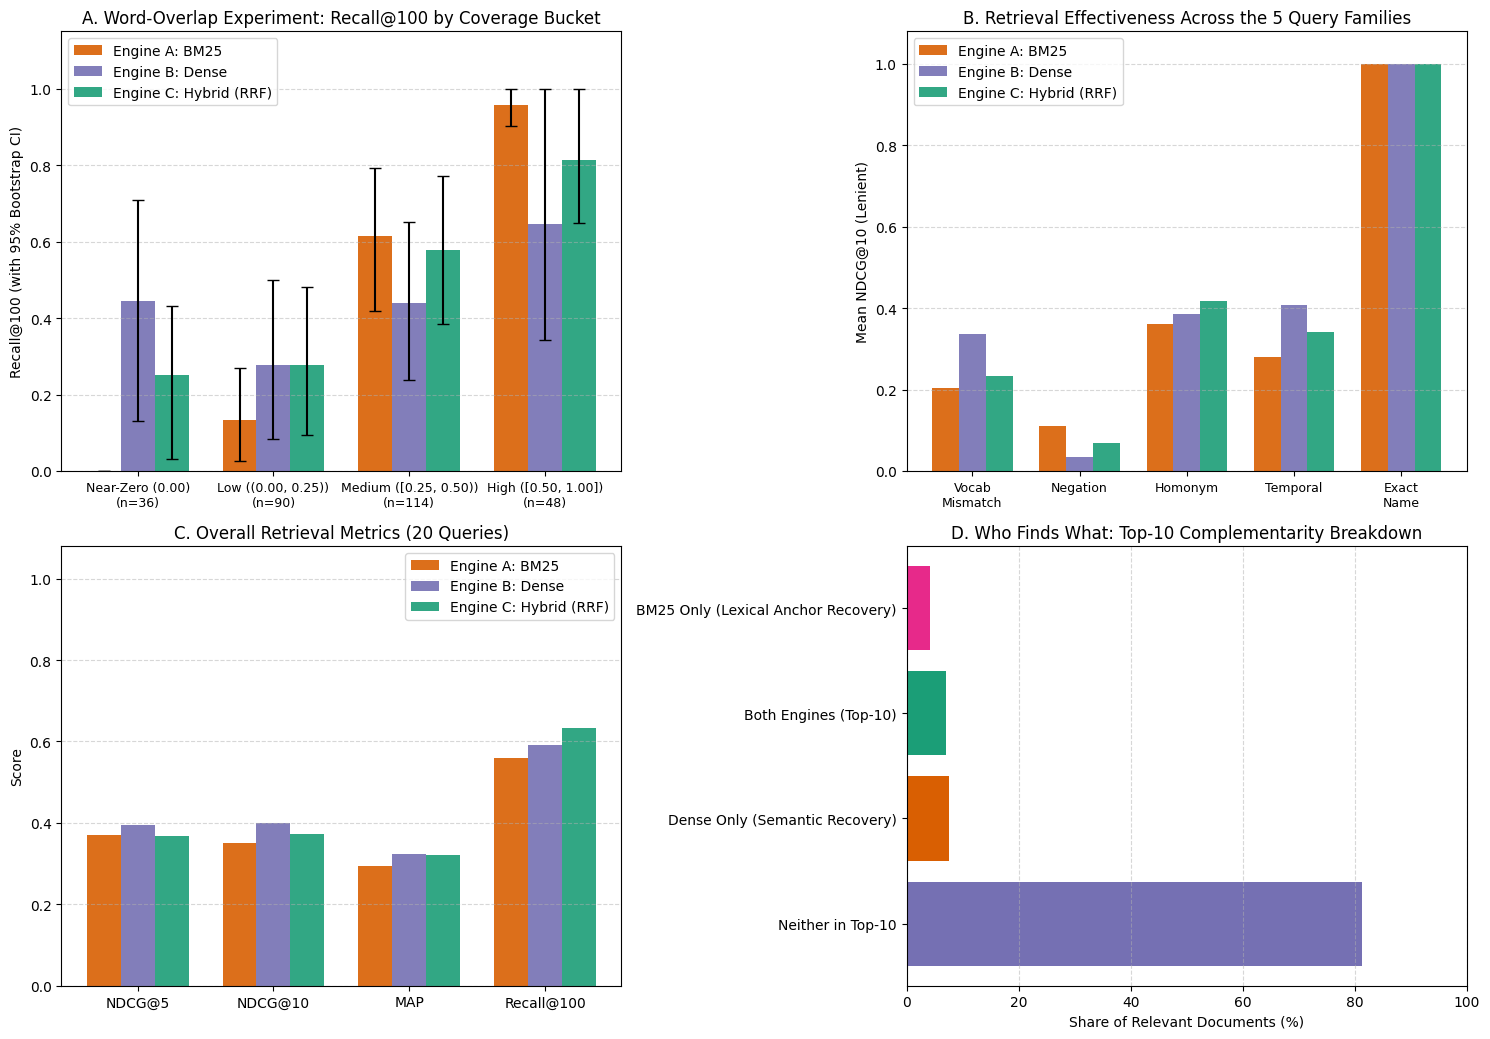

Saved final 3-engine figure to 'final_results_group4.png'.


In [12]:
outside_top10_pct = (1.0 - cov_df["BM25_R@10"].mean()) * 100.0
zero_overlap_pct = (cov_df["shared_terms"] == 0).mean() * 100.0
uncensored_ranks = cov_df["BM25_True_Rank"].dropna()
per_q_spearman = []
std_fp10, ora_fp10 = [], []
std_prf_ndcg10, ora_prf_ndcg10 = [], []

def expand_query_prf(query_str, feedback_indices, top_terms=8):
    q_base = set(preprocess_text(query_str, remove_stopwords=True, use_stemming=True))
    weights = Counter()
    for idx in feedback_indices:
        for tok in preprocess_text(df.loc[int(idx), "search_text"], remove_stopwords=True, use_stemming=True):
            if tok not in q_base and tok in bm25_engine.idf_table:
                weights[tok] += bm25_engine.idf_table[tok]
    added = " ".join(t for t, _ in weights.most_common(top_terms))
    return query_str + " " + added

for rule in QUERY_RULES:
    qid = rule["query_id"]
    q_text = rule["query"]
    qrel_map = qrels_graded[qid]
    b_all = bm25_engine.score_all(q_text)
    eval_docs = list(qrel_map.keys()) + hard_negatives[qid]
    if len(eval_docs) >= 3:
        s_vals = [float(b_all[i]) for i in eval_docs]
        g_vals = [int(qrel_map.get(i, 0)) for i in eval_docs]
        if len(set(s_vals)) > 1 and len(set(g_vals)) > 1:
            rho_q, _ = spearmanr(s_vals, g_vals)
            if not np.isnan(rho_q):
                per_q_spearman.append(float(rho_q))
    b_top100, _ = cached_rankings["Engine A: BM25"][qid]
    std_docs = list(b_top100[:10])
    ora_rel_docs = [int(i) for i in b_top100 if qrel_map.get(int(i), 0) >= 1]
    ora_docs = (ora_rel_docs + [int(i) for i in b_top100 if int(i) not in ora_rel_docs])[:10]
    std_fp10.append(np.mean([1 if qrel_map.get(int(i), 0) >= 1 else 0 for i in std_docs]) if std_docs else 0.0)
    ora_fp10.append(np.mean([1 if qrel_map.get(int(i), 0) >= 1 else 0 for i in ora_docs]) if ora_docs else 0.0)
    if std_docs:
        q_std_exp = expand_query_prf(q_text, std_docs)
        idx_std, _ = bm25_engine.search(q_std_exp, top_k=100)
        std_prf_ndcg10.append(compute_ndcg(idx_std, qrel_map, k=10, mode="lenient"))
    else:
        std_prf_ndcg10.append(0.0)
    if ora_rel_docs:
        q_ora_exp = expand_query_prf(q_text, ora_rel_docs[:10])
        idx_ora, _ = bm25_engine.search(q_ora_exp, top_k=100)
        ora_prf_ndcg10.append(compute_ndcg(idx_ora, qrel_map, k=10, mode="lenient"))
    else:
        ora_prf_ndcg10.append(compute_ndcg(b_top100, qrel_map, k=10, mode="lenient"))
albishre_summary = pd.DataFrame([
    {"Metric": "% Relevant Docs Outside BM25 Top-10", "HuffPost News Result": f"{outside_top10_pct:.2f}%", "Albishre (2026) Reference": "79.0%"},
    {"Metric": "% Relevant Docs with Zero Shared Query Words", "HuffPost News Result": f"{zero_overlap_pct:.2f}%", "Albishre (2026) Reference": "Vocabulary-gap blind spot"},
    {"Metric": "Uncensored Mean / Median BM25 Rank (when score > 0)", "HuffPost News Result": f"Mean: {uncensored_ranks.mean():.1f} | Median: {uncensored_ranks.median():.1f}", "Albishre (2026) Reference": "Mean rank 37.3"},
    {"Metric": "Mean Per-Query Spearman rho (BM25 Score vs. Grade)", "HuffPost News Result": f"{np.mean(per_q_spearman):.4f}", "Albishre (2026) Reference": "rho = 0.2030"},
    {"Metric": "Feedback Precision@10 (Standard Top-10 vs. Oracle Top-100)", "HuffPost News Result": f"Std: {np.mean(std_fp10):.4f} -> Oracle: {np.mean(ora_fp10):.4f} (+{np.mean(ora_fp10)-np.mean(std_fp10):.4f})", "Albishre (2026) Reference": "+0.324 FP@10 gap"},
    {"Metric": "Downstream BM25 NDCG@10 (Base vs. Std-PRF vs. Oracle-PRF)", "HuffPost News Result": f"Base: {lenient_overall.loc['Engine A: BM25', 'NDCG@10']:.4f} | Std-PRF: {np.mean(std_prf_ndcg10):.4f} | Oracle-PRF: {np.mean(ora_prf_ndcg10):.4f}", "Albishre (2026) Reference": "Oracle-PRF upper bound"}
])
print("=== 8. STRETCH OBJECTIVE: ORACLE-PRF & ALBISHRE (2026) DIAGNOSTICS ===")
display(albishre_summary)
def paired_wilcoxon(mode_str, eng1, eng2, metric="NDCG@10"):
    sub = eval_df[eval_df["mode"] == mode_str]
    s1 = sub[sub["engine"] == eng1].sort_values("query_id")[metric].to_numpy(dtype=np.float64)
    s2 = sub[sub["engine"] == eng2].sort_values("query_id")[metric].to_numpy(dtype=np.float64)
    diff = s1 - s2
    if np.all(np.isclose(diff, 0.0)):
        return 1.0, 0.0
    res = wilcoxon(diff, zero_method="zsplit", alternative="two-sided", method="approx")
    return float(res.pvalue), float(np.mean(diff))

w_rows = []
for e1, e2 in [
    ("Engine B: Dense", "Engine A: BM25"),
    ("Engine C: Hybrid (RRF)", "Engine A: BM25"),
    ("Engine C: Hybrid (RRF)", "Engine B: Dense"),
    ("Engine A: BM25", "Engine A (Stemming Off)")
]:
    p_len, d_len = paired_wilcoxon("lenient", e1, e2, "NDCG@10")
    p_str, d_str = paired_wilcoxon("strict", e1, e2, "NDCG@10")
    w_rows.append({
        "Comparison": f"{e1} vs. {e2}",
        "Lenient_NDCG@10_Diff": round(d_len, 4),
        "Lenient_p_value": round(p_len, 5),
        "Strict_NDCG@10_Diff": round(d_str, 4),
        "Strict_p_value": round(p_str, 5)
    })
print("\n=== 9. PAIRED WILCOXON SIGNED-RANK TESTS (LENIENT & STRICT MODES) ===")
display(pd.DataFrame(w_rows))
fig, axes = plt.subplots(2, 2, figsize=(15, 10.5))
w = 0.25
b_labels = bucket_table.index.tolist()
x_b = np.arange(len(b_labels))
short_b = [f"{b.split('. ', 1)[1]}\n(n={bucket_table.loc[b, 'n_relevant_pairs']})" for b in b_labels]
for offset, col_name, lbl, color in [
    (-w, "BM25_R@100", "Engine A: BM25", "#d95f02"),
    (0.0, "Dense_R@100", "Engine B: Dense", "#7570b3"),
    (w, "Hybrid_R@100", "Engine C: Hybrid (RRF)", "#1b9e77")
]:
    means, err_l, err_u = [], [], []
    for b in b_labels:
        sub = cov_df[cov_df["coverage_bucket"] == b]
        m = float(sub[col_name].mean())
        ci_l, ci_u = bootstrap_ci(sub, col_name)
        means.append(m)
        err_l.append(max(0.0, m - ci_l))
        err_u.append(max(0.0, ci_u - m))
    axes[0, 0].bar(x_b + offset, means, w, yerr=[err_l, err_u], capsize=4, label=lbl, color=color, alpha=0.9)
axes[0, 0].set_xticks(x_b)
axes[0, 0].set_xticklabels(short_b, fontsize=9)
axes[0, 0].set_ylim(0, 1.15)
axes[0, 0].set_ylabel("Recall@100 (with 95% Bootstrap CI)")
axes[0, 0].set_title("A. Word-Overlap Experiment: Recall@100 by Coverage Bucket")
axes[0, 0].legend()
axes[0, 0].grid(axis="y", linestyle="--", alpha=0.5)
families = ["Vocabulary mismatch", "Negation", "Homonym", "Temporal", "Exact name"]
x_f = np.arange(len(families))
for offset, eng_key, color in [
    (-w, "Engine A: BM25", "#d95f02"),
    (0.0, "Engine B: Dense", "#7570b3"),
    (w, "Engine C: Hybrid (RRF)", "#1b9e77")
]:
    vals = [float(family_table.loc[f, ("NDCG@10", eng_key)]) for f in families]
    axes[0, 1].bar(x_f + offset, vals, w, label=eng_key, color=color, alpha=0.9)

axes[0, 1].set_xticks(x_f)
axes[0, 1].set_xticklabels(["Vocab\nMismatch", "Negation", "Homonym", "Temporal", "Exact\nName"], fontsize=9)
axes[0, 1].set_ylim(0, 1.08)
axes[0, 1].set_ylabel("Mean NDCG@10 (Lenient)")
axes[0, 1].set_title("B. Retrieval Effectiveness Across the 5 Query Families")
axes[0, 1].legend()
axes[0, 1].grid(axis="y", linestyle="--", alpha=0.5)
m_cols = ["NDCG@5", "NDCG@10", "MAP", "Recall@100"]
x_m = np.arange(len(m_cols))
for offset, eng_key, color in [
    (-w, "Engine A: BM25", "#d95f02"),
    (0.0, "Engine B: Dense", "#7570b3"),
    (w, "Engine C: Hybrid (RRF)", "#1b9e77")
]:
    vals = [float(lenient_overall.loc[eng_key, c]) for c in m_cols]
    axes[1, 0].bar(x_m + offset, vals, w, label=eng_key, color=color, alpha=0.9)
axes[1, 0].set_xticks(x_m)
axes[1, 0].set_xticklabels(m_cols)
axes[1, 0].set_ylim(0, 1.08)
axes[1, 0].set_ylabel("Score")
axes[1, 0].set_title("C. Overall Retrieval Metrics (20 Queries)")
axes[1, 0].legend()
axes[1, 0].grid(axis="y", linestyle="--", alpha=0.5)
palette = ["#7570b3", "#d95f02", "#1b9e77", "#e7298a"][:len(comp_table)]
axes[1, 1].barh(comp_table["Who Finds What (Top-10)"], comp_table["Share (%)"], color=palette)
axes[1, 1].set_xlim(0, 100)
axes[1, 1].set_xlabel("Share of Relevant Documents (%)")
axes[1, 1].set_title("D. Who Finds What: Top-10 Complementarity Breakdown")
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("final_results_group4.png", dpi=300)
plt.show()
print("Saved final 3-engine figure to 'final_results_group4.png'.")